<a href="https://colab.research.google.com/github/Vitela-debug/Colab_S1_Clase-de-progralaci-n_273522_TVB/blob/main/273522_Tania_Vitela_WK12_Act03.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Actividad: Árbol de Decisión para Regresión


**Objetivo**

Analizar el comportamiento de un modelo de árbol de decisión en un problema de regresión, evaluando su capacidad de generalización mediante el estudio del sobreajuste, la profundidad del árbol y la poda.

**Tania Vitela Barraza**

**273522**



**Dataset**

Se utilizará el dataset California Housing, disponible en scikit-learn.

**Variable objetivo:** MedHouseVal

# 1. Carga y exploración de datos

- Cargar el dataset en un DataFrame

- Identificar la variable objetivo (MedHouseVal)

- Analizar la estructura del dataset (info, describe)

- Visualizar la distribución de la variable objetivo

In [30]:

# Importar las librerías necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, r2_score


# Cargar el dataset
housing = fetch_california_housing(as_frame=True)

# Convertir los datos en un DataFrame
df = housing.frame

# Mostrar las primeras filas
df.head()


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


---
---
* El código del ejercicio importa las librerías que se utilizarán para realizar la actividad: Pandas para organizar y analizar los datos, NumPy para realizar operaciones matemáticas, Matplotlib y Seaborn para crear gráficas, y Scikit-learn para cargar el dataset California Housing. Después se convierte la información en un DataFrame y se muestran los primeros registros.
---
---


In [31]:

# Identificar la variable objetivo
print("Variable objetivo: MedHouseVal")

# Mostrar las columnas del dataset
print(df.columns)

# Separar variables independientes y dependiente
X = df.drop("MedHouseVal", axis=1)
y = df["MedHouseVal"]

print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)


Variable objetivo: MedHouseVal
Index(['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup',
       'Latitude', 'Longitude', 'MedHouseVal'],
      dtype='object')
Dimensiones de X: (20640, 8)
Dimensiones de y: (20640,)


---
---
* El código identifica MedHouseVal como la variable que se quiere predecir. Se separan los datos en X, que contiene las características, y y, que contiene los valores de las viviendas.
---
---

In [32]:

# Información general del dataset
df.info()

# Estadísticas descriptivas
df.describe()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


---
---
* El código utiliza `info()` para conocer la estructura y los tipos de datos, y `describe() `para obtener estadísticas como el promedio, mínimo y máximo.
---
---

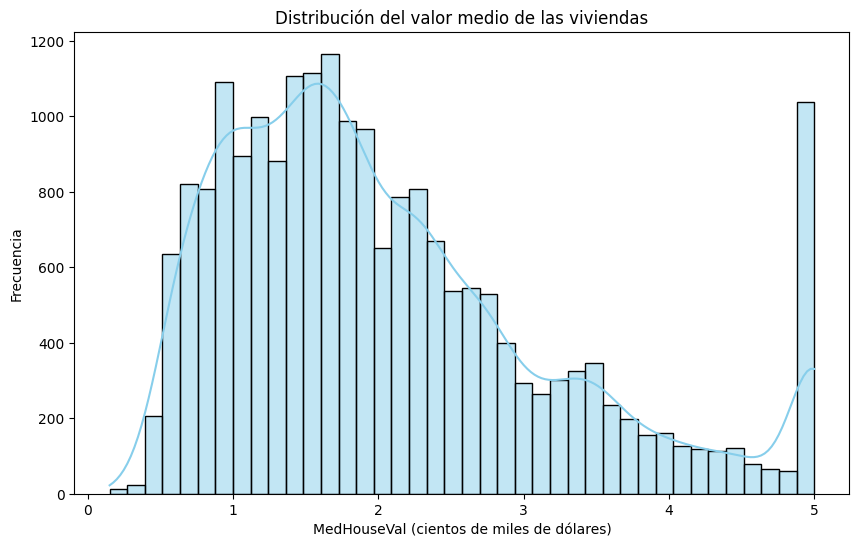

In [33]:

# Configurar el tamaño de la gráfica
plt.figure(figsize=(10, 6))

# Crear histograma
sns.histplot(df["MedHouseVal"], bins=40, kde=True, color="skyblue")

# Personalizar la gráfica
plt.title("Distribución del valor medio de las viviendas")
plt.xlabel("MedHouseVal (cientos de miles de dólares)")
plt.ylabel("Frecuencia")

plt.show()


La gráfica muestra que la mayoría de los valores de las viviendas se concentran entre 0.7 y 2.5. También se observa que, conforme aumenta el valor de las viviendas, la frecuencia disminuye. Además, destaca un pico al final de la gráfica, cerca de 5, lo que indica que varios valores alcanzaron el límite máximo del dataset. Esto muestra que la distribución no es uniforme y presenta una inclinación hacia la derecha.

---
---
* El código genera un histograma que permite visualizar la distribución de los valores medios de las viviendas, mostrando cuáles son los rangos de precios más frecuentes y cómo varía la cantidad de viviendas en cada rango.
---
---

# 2. Preparación de datos
- Definir:

  - X: variables predictoras

  - y: variable objetivo

- Dividir los datos en entrenamiento (80%) y prueba (20%)

In [34]:
# Definir las variables predictoras y la variable objetivo
X = df.drop("MedHouseVal", axis=1)
y = df["MedHouseVal"]

---
---
* El código utiliza X para almacenar las variables predictoras, es decir, las características que ayudarán al modelo a realizar las predicciones. Mientras que y almacena la variable objetivo MedHouseVal, que contiene los valores de las viviendas que se desean predecir.
---
---

In [35]:

# Dividir los datos: 80% entrenamiento y 20% prueba
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# Mostrar las dimensiones de los conjuntos
print("Datos de entrenamiento:", X_train.shape)
print("Datos de prueba:", X_test.shape)

Datos de entrenamiento: (16512, 8)
Datos de prueba: (4128, 8)


---
---
* El código utiliza train_test_split para dividir los datos en dos grupos: 80% para entrenar el modelo y 20% para probar su rendimiento. Se utiliza random_state=42 para que la división sea siempre la misma al ejecutar el código.
---
---

# 3. Modelo base
- Entrenar un árbol de decisión sin restricciones (max_depth=None)

- Evaluar el modelo usando:

  - RMSE

  - R²

- Comparar desempeño en entrenamiento y prueba

- Determinar si existe sobreajuste

In [36]:
# Crear el modelo de árbol de decisión
modelo = DecisionTreeRegressor(max_depth=None, random_state=42)

# Entrenar el modelo
modelo.fit(X_train, y_train)

DecisionTreeRegressor(random_state=42)

---
---
* El código usa DecisionTreeRegressor para crear un modelo de regresión. Se establece max_depth=None para que el árbol pueda crecer sin límite de profundidad. Después, con fit() se entrena el modelo utilizando los datos de entrenamiento.
---
---

In [37]:
# Realizar predicciones
y_train_pred = modelo.predict(X_train)
y_test_pred = modelo.predict(X_test)

# Calcular RMSE
rmse_train = np.sqrt(mean_squared_error(y_train, y_train_pred))
rmse_test = np.sqrt(mean_squared_error(y_test, y_test_pred))

# Calcular R²
r2_train = r2_score(y_train, y_train_pred)
r2_test = r2_score(y_test, y_test_pred)

# Mostrar resultados
print("RMSE entrenamiento:", rmse_train)
print("RMSE prueba:", rmse_test)

print("R² entrenamiento:", r2_train)
print("R² prueba:", r2_test)

RMSE entrenamiento: 3.218325866275131e-16
RMSE prueba: 0.7037294974840077
R² entrenamiento: 1.0
R² prueba: 0.622075845135081


Al comparar los resultados, se observa que en entrenamiento el modelo obtuvo un RMSE de 0.0000 y un R² de 1.000, mientras que en prueba obtuvo un RMSE de 0.7037 y un R² de 0.6221. Esto significa que el modelo funciona mucho mejor con los datos que utilizó para aprender que con los datos nuevos.

---
---
* El código realiza predicciones con los datos de entrenamiento y prueba. Después calcula dos métricas: RMSE, que mide el error de las predicciones, y R², que indica qué tan bien el modelo explica los valores reales.
---
---

In [38]:
resultados = pd.DataFrame({
    "Conjunto": ["Entrenamiento", "Prueba"],
    "RMSE": [rmse_train, rmse_test],
    "R²": [r2_train, r2_test]
})

resultados

,Conjunto,RMSE,R²
0,Entrenamiento,3.218326e-16,1.000000
1,Prueba,7.037295e-01,0.622076


Sí existe sobreajuste, porque el modelo aprendió prácticamente todos los datos de entrenamiento, pero no logró mantener el mismo rendimiento al realizar predicciones con datos de prueba. Esto indica que el árbol tiene demasiada profundidad y necesita limitarse o aplicarle poda para mejorar sus resultados.

---
---
* El código crea una tabla para comparar los resultados del modelo en entrenamiento y prueba. Esto permite observar si el árbol funciona de manera similar con los datos que conoce y con los que no ha visto.
---
---

# 4. Análisis Bias–Variance
- Entrenar múltiples modelos variando el parámetro max_depth de 1 a 21.

- Graficar el error (RMSE) en entrenamiento y prueba

- Identificar el punto donde el modelo generaliza mejor

In [39]:
# Crear listas para guardar los errores
rmse_train = []
rmse_test = []
profundidades = range(1, 22)

# Entrenar modelos con diferentes profundidades
for profundidad in profundidades:
    modelo = DecisionTreeRegressor(
        max_depth=profundidad,
        random_state=42
    )

    modelo.fit(X_train, y_train)

    # Realizar predicciones
    pred_train = modelo.predict(X_train)
    pred_test = modelo.predict(X_test)

    # Calcular RMSE
    rmse_train.append(np.sqrt(mean_squared_error(y_train, pred_train)))
    rmse_test.append(np.sqrt(mean_squared_error(y_test, pred_test)))

---
---
* El código entrena varios árboles de decisión modificando su profundidad desde 1 hasta 21. En cada modelo calcula el error RMSE tanto en entrenamiento como en prueba, para comparar su rendimiento.
---
---

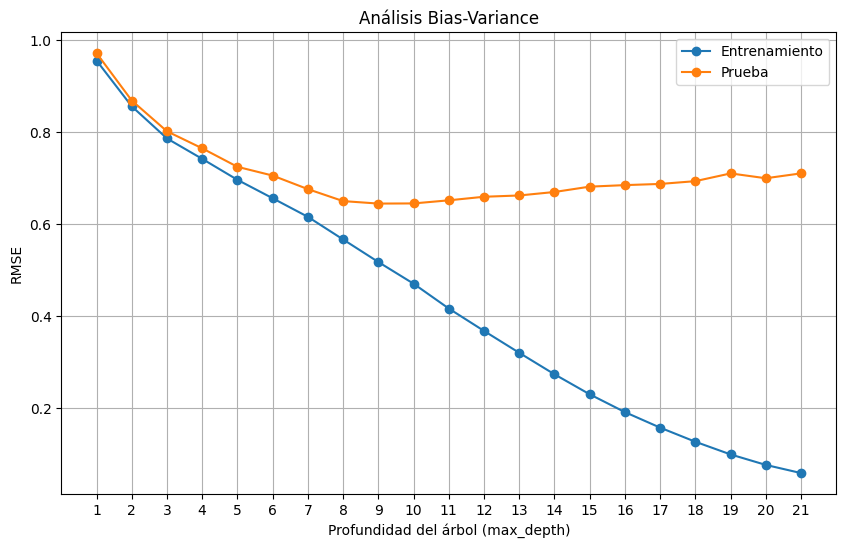

In [40]:

plt.figure(figsize=(10, 6))

plt.plot(profundidades, rmse_train, marker='o',
         label='Entrenamiento')

plt.plot(profundidades, rmse_test, marker='o',
         label='Prueba')

plt.xlabel("Profundidad del árbol (max_depth)")
plt.ylabel("RMSE")
plt.title("Análisis Bias-Variance")
plt.xticks(profundidades)
plt.legend()
plt.grid()
plt.show()


El análisis d muestra que entre las profundidades 1 y 6 el modelo sufre de subajuste (underfitting) por ser demasiado simple para capturar los patrones esenciales de los datos (alto sesgo), mientras que a partir de una profundidad mayor a 10 cae en sobreajuste (overfitting), memorizando el ruido del entrenamiento y perdiendo capacidad de generalización (alta varianza); por lo tanto, el punto óptimo de equilibrio se encuentra en una profundidad de 9 a 10, donde el error de prueba alcanza su valor mínimo ($\text{RMSE} \approx 0.645$) y maximiza su desempeño predictivo.

---
---
* El código genera una gráfica que compara los errores RMSE de entrenamiento y prueba para cada profundidad del árbol. Esto permite observar cómo cambia el rendimiento del modelo cuando aumenta su profundidad.
---
---

In [41]:
# Encontrar la profundidad con menor error en prueba
mejor_indice = np.argmin(rmse_test)

print("Mejor profundidad:", list(profundidades)[mejor_indice])
print("Menor RMSE en prueba:", rmse_test[mejor_indice])

Mejor profundidad: 9
Menor RMSE en prueba: 0.6442578164688181


---
---
* El código busca cuál de los modelos obtuvo el menor error RMSE en los datos de prueba. De esta manera, identifica la profundidad que ofrece el mejor rendimiento al trabajar con datos que no utilizó durante el entrenamiento.
---
---

# 5. Poda del árbol
- Aplicar cost-complexity pruning (ccp_alpha)

- Evaluar distintos valores de ccp_alpha con ccp_alphas = ccp_alphas[::5]

- Analizar su efecto en el error del modelo

In [53]:
# Entrenar un árbol para obtener los valores de poda
modelo_base = DecisionTreeRegressor(random_state=42)
modelo_base.fit(X_train, y_train)

# Obtener los valores de ccp_alpha
path = modelo_base.cost_complexity_pruning_path(X_train, y_train)

ccp_alphas = path.ccp_alphas

# Seleccionar un valor cada cinco posiciones
ccp_alphas = ccp_alphas[::10] #Cambio a 20 para poder correr la siguiente parte del programa
print("Cantidad de valores a evaluar:", len(ccp_alphas))

Cantidad de valores a evaluar: 1484


---
---
* El código obtiene los diferentes valores de ccp_alpha que se pueden utilizar para podar el árbol. Este parámetro controla qué tanto se simplifica el modelo, eliminando ramas que aportan poco a su rendimiento. Después se selecciona un valor de cada cinco posiciones para analizar diferentes niveles de poda.
---
---

In [54]:
# Crear listas para guardar los errores
rmse_train_pruning = []
rmse_test_pruning = []

# Evaluar cada valor de ccp_alpha
for alpha in ccp_alphas:
    modelo = DecisionTreeRegressor(
        random_state=42,
        ccp_alpha=alpha,
        max_depth=15 #se limita la profunidad porque no termina de cargar con valores mayores
    )

    modelo.fit(X_train, y_train)

    pred_train = modelo.predict(X_train)
    pred_test = modelo.predict(X_test)

    rmse_train_pruning.append(
        np.sqrt(mean_squared_error(y_train, pred_train))
    )

    rmse_test_pruning.append(
        np.sqrt(mean_squared_error(y_test, pred_test))
    )

---
---
* El código entrena diferentes árboles utilizando los valores de ccp_alpha seleccionados. Para cada modelo calcula el error RMSE en entrenamiento y prueba, con la finalidad de observar cómo cambia su rendimiento al aplicar diferentes niveles de poda.
---
---


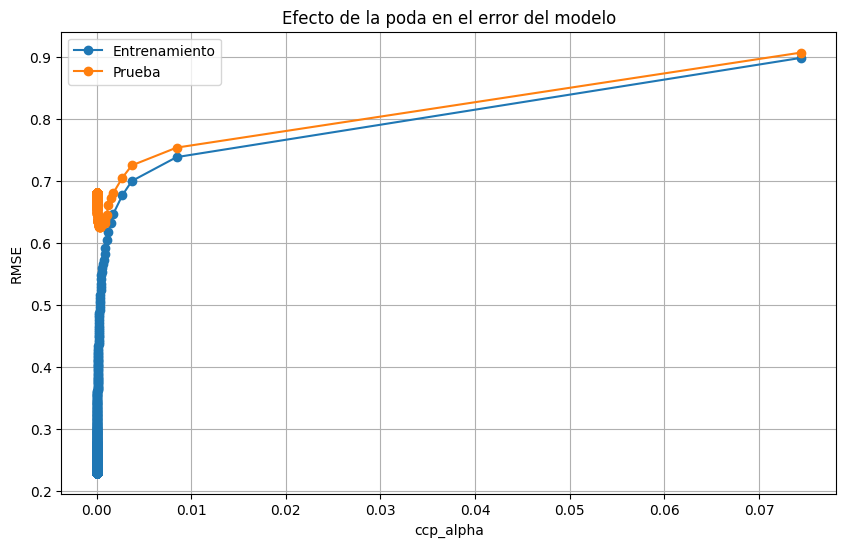

In [55]:
plt.figure(figsize=(10, 6))

plt.plot(ccp_alphas, rmse_train_pruning,
         marker='o', label='Entrenamiento')

plt.plot(ccp_alphas, rmse_test_pruning,
         marker='o', label='Prueba')

plt.xlabel("ccp_alpha")
plt.ylabel("RMSE")
plt.title("Efecto de la poda en el error del modelo")
plt.legend()
plt.grid()
plt.show()

 La gráfica demuestra el efecto de la poda por complejidad de costo (Cost-Complexity Pruning) mediante el parámetro ccp_alpha: con valores cercanos a cero el árbol no sufre penalización y sobreajusta los datos (overfitting), memorizando el ruido con un error de entrenamiento mínimo pero un error de prueba elevado; al aplicar un valor óptimo muy pequeño (apenas por encima de 0), la poda elimina las ramas redundantes y permite que el error de prueba alcance su punto mínimo de generalización ($\text{RMSE} \approx 0.62$); finalmente, valores de ccp_alpha superiores a $0.005$ causan una sobrepoda excesiva que despoja al modelo de su estructura predictiva, provocando subajuste (underfitting) y disparando drásticamente el error tanto en entrenamiento como en prueba hacia un RMSE cercano a 0.90


---
---
* El código genera una gráfica que compara los errores de entrenamiento y prueba con diferentes valores de poda. Esto permite observar si al simplificar el árbol disminuye el sobreajuste o si, por el contrario, el modelo pierde capacidad de aprendizaje.
---
---


# 6. Interpretación de resultados

Responder de manera justificada:

- ¿El modelo base presenta sobreajuste? Explique

- ¿Cómo afecta la profundidad del árbol al error?

- ¿Qué efecto tiene la poda en el modelo?

- ¿Cuál configuración produce el mejor desempeño?

- ¿Qué variables son más relevantes según el modelo?

**1. ¿El modelo base presenta sobreajuste? Explique.**

Sí, el modelo base presenta sobreajuste porque obtuvo un RMSE de 0.0000 y un R² de 1.0000 en entrenamiento, lo que significa que aprendió prácticamente todos los datos. Sin embargo, en prueba obtuvo un RMSE de 0.7037 y un R² de 0.6221. Esto demuestra que tiene dificultades para realizar predicciones con datos nuevos, debido a que el árbol creció demasiado y aprendió los datos de entrenamiento casi de memoria.

**2. ¿Cómo afecta la profundidad del árbol al error?**

La profundidad influye directamente en el rendimiento del modelo. Cuando el árbol tiene poca profundidad, presenta subajuste porque no logra aprender suficientes patrones de los datos. Conforme aumenta la profundidad, el error disminuye y el modelo mejora sus predicciones. Sin embargo, cuando crece demasiado, comienza a presentar sobreajuste. En los resultados obtenidos, la profundidad de 9 fue la mejor, con un RMSE de 0.6443 en prueba.

**3. ¿Qué efecto tiene la poda en el modelo?**

La poda permite reducir la complejidad del árbol eliminando ramas que aportan poco a las predicciones. En los resultados obtenidos se observa que, al aplicar la poda, el error de prueba disminuye hasta alcanzar aproximadamente un RMSE de 0.62. Sin embargo, cuando el valor de ccp_alpha aumenta demasiado, el árbol pierde información importante y comienza a presentar subajuste. Por eso es importante encontrar un nivel adecuado de poda.

**4. ¿Cuál configuración produce el mejor desempeño?**

De acuerdo con los resultados obtenidos, el árbol con una profundidad de 9 presenta un buen desempeño, con un RMSE de 0.6443 en prueba. Por otro lado, la gráfica de poda muestra un error aproximado de 0.62, por lo que la configuración con poda parece ofrecer un mejor resultado.

Para determinar cuál es la mejor configuración definitiva, sería necesario identificar el valor exacto de ccp_alpha que produjo ese RMSE y compararlo con el modelo de profundidad 9 utilizando las mismas condiciones de evaluación.

**5. ¿Qué variables son más relevantes según el modelo?**

Las variables más relevantes son aquellas que ayudan al árbol a realizar mejores predicciones sobre el valor de las viviendas. En este dataset destacan:

- MedInc: ingreso medio de los habitantes del distrito.

- Latitude: ubicación geográfica de las viviendas.

- Longitude: ubicación geográfica de las viviendas.

- AveOccup: promedio de personas por hogar.

Estas variables pueden tener una mayor influencia en la predicción del precio medio de las viviendas ya que aportan información que ayuda al modelo a estimar el valor medio de las viviendas.